# Numerical differentiation

We begin with the simplest difference formulas, derive more general formulas from polynomial interpolation, and discuss the effect of errors in function values.

We assume familiarity with the polynomial interpolation problem and its basic properties.

**Lecture outline:** first derivatives; second derivatives; interpolation-based formulas; other approximations; conditioning and step selection.


## The simplest formulas for numerical differentiation


### Calculating the first derivative

**Definition: the derivative as a limit.**

Let $f:U(x_0)\subset\mathbb R\to\mathbb R$ be defined on a neighborhood $U(x_0)$ of $x_0$.
The derivative of $f$ at $x_0$ is the following limit, provided it exists:
$$
\begin{aligned}
f'(x_0)&=\lim_{x\to x_0}\frac{f(x)-f(x_0)}{x-x_0}\\
&=\lim_{\Delta x\to0}\frac{f(x_0+\Delta x)-f(x_0)}{\Delta x}
=\lim_{\Delta x\to0}\frac{\Delta f}{\Delta x}.
\end{aligned}\tag{1}
$$
Here $\Delta x\ne0$ is the argument increment and $\Delta f=f(x_0+\Delta x)-f(x_0)$ is the corresponding function increment.
At a general point $x$, the same definition gives
$$
f'(x)=\lim_{\Delta x\to0}\frac{f(x+\Delta x)-f(x)}{\Delta x}.\tag{2}
$$

Fix a step $h>0$. All nodes used below must lie in the domain of $f$.
Replacing the limiting increment by $h$ or $-h$ gives two simple approximations.

**Definition 1: forward (right) difference.**
$$
f'(x)\approx D_+f(x;h)=\frac{f(x+h)-f(x)}h.\tag{3}
$$

**Definition 2: backward (left) difference.**
$$
f'(x)\approx D_-f(x;h)=\frac{f(x)-f(x-h)}h.\tag{4}
$$

Let us introduce their signed approximation errors:
$$
r_+(x,h)=f'(x)-\frac{f(x+h)-f(x)}h,\tag{5}
$$
$$
r_-(x,h)=f'(x)-\frac{f(x)-f(x-h)}h.\tag{6}
$$
The sign convention is **exact value minus approximation**. Absolute errors are $|r_+|$ and $|r_-|$.

**Error estimate.** Assume $f\in C^2([x-h,x+h])$, meaning that $f$ has two continuous derivatives on this interval. Taylor's theorem gives
$$
f(x\pm h)=f(x)\pm f'(x)h+\frac{f''(\xi_\pm)}2h^2,\tag{7}
$$
where $\xi_+\in(x,x+h)$ and $\xi_-\in(x-h,x)$.
Substitution into (5) and (6) gives
$r_+=-f''(\xi_+)h/2$ and $r_-=f''(\xi_-)h/2$. Hence
$$
|r_+(x,h)|\le\frac{M_{2,+}}2h,\qquad M_{2,+}=\max_{t\in[x,x+h]}|f''(t)|,\tag{8}
$$
$$
|r_-(x,h)|\le\frac{M_{2,-}}2h,\qquad M_{2,-}=\max_{t\in[x-h,x]}|f''(t)|.\tag{9}
$$
Each one-sided formula needs $C^2$ smoothness only on its own interval.
Both formulas have accuracy of at least first order: their errors are $\mathcal O(h)$ as $h\to0$, for a fixed smooth function.


#### Geometric interpretation

Let $N_0=(x,f(x))$, $N_-=(x-h,f(x-h))$, and $N_+=(x+h,f(x+h))$ be points on the graph.
The derivative $f'(x)$ is the slope of the tangent at $N_0$.
The forward and backward differences are the slopes of the secants through $N_0,N_+$ and $N_-,N_0$, respectively.
The central difference is the slope of the secant through $N_-,N_+$.

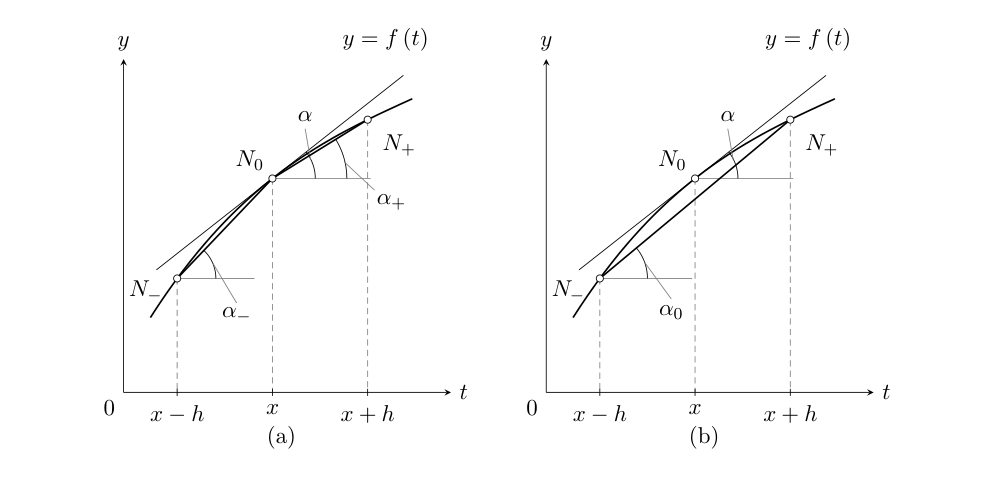

The central secant need not pass through $N_0$. Its slope is what approximates the tangent slope.


**Definition 3: central difference for the first derivative.**
$$
f'(x)\approx D_0f(x;h)=\frac{f(x+h)-f(x-h)}{2h}.\tag{10}
$$

Let us estimate its signed error:
$$
r_0(x,h)=f'(x)-\frac{f(x+h)-f(x-h)}{2h}.\tag{11}
$$
Assume $f\in C^3([x-h,x+h])$. Taylor's theorem gives
$$
f(x\pm h)=f(x)\pm f'(x)h+\frac{f''(x)}2h^2
\pm\frac{f^{(3)}(\xi_\pm)}6h^3.\tag{12}
$$
The even terms cancel when we subtract, so
$$
r_0(x,h)=-\frac{f^{(3)}(\xi_+)+f^{(3)}(\xi_-)}{12}h^2.\tag{13}
$$
Therefore,
$$
|r_0(x,h)|\le\frac{M_3}{6}h^2,\qquad
M_3=\max_{t\in[x-h,x+h]}|f^{(3)}(t)|.\tag{14}
$$
The central formula has accuracy of at least second order.
This improvement requires the stated smoothness, as well as symmetry.

Higher-order formulas are obtained by using additional nodes and cancelling more Taylor terms.
For example,
$$
f'(x)\approx D_4f(x;h)=
\frac{f(x-2h)-8f(x-h)+8f(x+h)-f(x+2h)}{12h}\tag{15}
$$
has fourth-order accuracy when $f\in C^5$ on a fixed neighborhood containing the nodes.
The subscript $4$ here records the order of accuracy.


**Example 1.** Let $f(x)=e^x$ on $[0,1]$ and use a uniform grid with step $h=0.2$.
We calculate with full floating-point values; the printed decimals are for display only.


In [1]:
import math

# Build the grid using integer indices, so the endpoint is not lost
# through repeated floating-point addition.
a, b = 0.0, 1.0
n_intervals = 5
h = (b - a) / n_intervals
x_values = [a + i * h for i in range(n_intervals + 1)]
f_values = [math.exp(point) for point in x_values]

print(f"{'x':>5} {'f(x) = exp(x)':>18}")
print('-' * 24)
for point, value in zip(x_values, f_values):
    print(f"{point:5.1f} {value:18.9f}")


    x      f(x) = exp(x)
------------------------
  0.0        1.000000000
  0.2        1.221402758
  0.4        1.491824698
  0.6        1.822118800
  0.8        2.225540928
  1.0        2.718281828


In [2]:
# Use one-sided differences at the endpoints and central differences inside.
n_nodes = len(x_values)
first_derivatives = []
print(f"{'x':>5} {'method':>10} {'approximation':>16} {'exact':>16} {'absolute error':>17}")
print('-' * 69)
for i, point in enumerate(x_values):
    if i == 0:
        approximation = (f_values[i + 1] - f_values[i]) / h
        method = 'forward'
    elif i == n_nodes - 1:
        approximation = (f_values[i] - f_values[i - 1]) / h
        method = 'backward'
    else:
        approximation = (f_values[i + 1] - f_values[i - 1]) / (2 * h)
        method = 'central'
    first_derivatives.append(approximation)
    exact = math.exp(point)
    print(f"{point:5.1f} {method:>10} {approximation:16.9f} {exact:16.9f} {abs(approximation - exact):17.6e}")


    x     method    approximation            exact    absolute error
---------------------------------------------------------------------
  0.0    forward      1.107013791      1.000000000      1.070138e-01
  0.2    central      1.229561744      1.221402758      8.158986e-03
  0.4    central      1.501790106      1.491824698      9.965408e-03
  0.6    central      1.834290577      1.822118800      1.217178e-02
  0.8    central      2.240407570      2.225540928      1.486664e-02
  1.0   backward      2.463704500      2.718281828      2.545773e-01


The a priori bounds can be evaluated before forming the difference quotients.
At $x=0$, formula (8) gives
$$
|r_+(0,0.2)|\le\frac12 e^{0.2}(0.2)
\approx0.122140276.\tag{16}
$$
This is an upper bound; the actual absolute error in the table is about $0.107013791$.
At $x=0.2$, formula (14) gives
$$
|r_0(0.2,0.2)|\le\frac16 e^{0.4}(0.2)^2
\approx0.009945498.\tag{17}
$$

At $x=0.4$ and $x=0.6$, all four nodes needed for (15) are available:
$$
f'(x)\approx
\frac{f(x-2h)-8f(x-h)+8f(x+h)-f(x+2h)}{12h}.\tag{18}
$$
The table below compares this formula with the exact derivative.
Its absolute errors are about $7.99\cdot10^{-5}$ and $9.76\cdot10^{-5}$.


In [3]:
# Fourth-order first derivative: only nodes with two neighbors on each side.
print(f"{'x':>5} {'fourth-order':>16} {'exact':>16} {'absolute error':>17}")
print('-' * 57)
for i in range(2, len(x_values) - 2):
    approximation = (f_values[i - 2] - 8*f_values[i - 1]
                     + 8*f_values[i + 1] - f_values[i + 2]) / (12*h)
    exact = math.exp(x_values[i])
    print(f"{x_values[i]:5.1f} {approximation:16.9f} {exact:16.9f} {abs(approximation - exact):17.6e}")


    x     fourth-order            exact    absolute error
---------------------------------------------------------
  0.4      1.491744754      1.491824698      7.994375e-05
  0.6      1.822021157      1.822118800      9.764351e-05


### Calculating the second derivative

**Definition 4: central second difference.**
$$
f''(x)\approx D_2f(x;h)=\frac{f(x-h)-2f(x)+f(x+h)}{h^2}.\tag{19}
$$
Here $D_2$ denotes the approximation to the second derivative.
Its signed error is
$$
r_2(x,h)=f''(x)-\frac{f(x-h)-2f(x)+f(x+h)}{h^2}.\tag{20}
$$
Assume $f\in C^4([x-h,x+h])$. Substituting the Taylor expansions
$$
f(x\pm h)=f(x)\pm f'(x)h+\frac{f''(x)}2h^2
\pm\frac{f^{(3)}(x)}6h^3+\frac{f^{(4)}(\xi_\pm)}{24}h^4\tag{21}
$$
gives
$$
r_2(x,h)=-\frac{f^{(4)}(\xi_+)+f^{(4)}(\xi_-)}{24}h^2.\tag{22}
$$
Therefore,
$$
|r_2(x,h)|\le\frac{M_4}{12}h^2,\qquad
M_4=\max_{t\in[x-h,x+h]}|f^{(4)}(t)|.\tag{23}
$$
The three-point formula has accuracy of at least second order.

A five-point formula is
$$
f''(x)\approx
\frac{-f(x-2h)+16f(x-h)-30f(x)+16f(x+h)-f(x+2h)}{12h^2}.\tag{24}
$$
It has fourth-order accuracy if $f\in C^6$ on a fixed neighborhood containing all five nodes.


**Example 2.** Using the same full-precision samples of $f(x)=e^x$, let us approximate $f''(x)$ at the interior nodes with (19).
A dash means that the central formula needs a value outside the supplied table.


In [4]:
print(f"{'x':>5} {'three-point':>16} {'exact':>16} {'absolute error':>17}")
print('-' * 57)
second_derivatives_three = []
for i, point in enumerate(x_values):
    exact = math.exp(point)
    if i == 0 or i == len(x_values) - 1:
        second_derivatives_three.append(None)
        print(f"{point:5.1f} {'--':>16} {exact:16.9f} {'--':>17}")
    else:
        approximation = (f_values[i - 1] - 2*f_values[i] + f_values[i + 1]) / h**2
        second_derivatives_three.append(approximation)
        print(f"{point:5.1f} {approximation:16.9f} {exact:16.9f} {abs(approximation - exact):17.6e}")


    x      three-point            exact    absolute error
---------------------------------------------------------
  0.0               --      1.000000000                --
  0.2      1.225479533      1.221402758      4.076775e-03
  0.4      1.496804082      1.491824698      4.979384e-03
  0.6      1.828200634      1.822118800      6.081833e-03
  0.8      2.232969297      2.225540928      7.428368e-03
  1.0               --      2.718281828                --


**At the endpoints.** The absence of a central formula does not prevent differentiation.
On a uniform grid $x_j=a+jh$, $j=0,\ldots,n$, with $n\ge3$, four-point one-sided formulas are
$$
f''(x_0)\approx\frac{2y_0-5y_1+4y_2-y_3}{h^2},\qquad
f''(x_n)\approx\frac{2y_n-5y_{n-1}+4y_{n-2}-y_{n-3}}{h^2},\tag{25}
$$
where $y_j=f(x_j)$.
They are second-order accurate for $f\in C^4$ on the corresponding shrinking intervals.
They use four nodes, rather than the three nodes of the central formula.


**Example 2.1.** Let us now use the five-point formula:
$$
f''(x)\approx
\frac{-f(x-2h)+16f(x-h)-30f(x)+16f(x+h)-f(x+2h)}{12h^2}.\tag{26}
$$
This is the same formula as (24). It needs two neighboring nodes on each side.


In [5]:
print(f"{'x':>5} {'five-point':>16} {'exact':>16} {'absolute error':>17}")
print('-' * 57)
second_derivatives_five = []
for i, point in enumerate(x_values):
    exact = math.exp(point)
    if i < 2 or i > len(x_values) - 3:
        second_derivatives_five.append(None)
        print(f"{point:5.1f} {'--':>16} {exact:16.9f} {'--':>17}")
    else:
        approximation = (-f_values[i - 2] + 16*f_values[i - 1] - 30*f_values[i]
                         + 16*f_values[i + 1] - f_values[i + 2]) / (12*h**2)
        second_derivatives_five.append(approximation)
        print(f"{point:5.1f} {approximation:16.9f} {exact:16.9f} {abs(approximation - exact):17.6e}")


    x       five-point            exact    absolute error
---------------------------------------------------------
  0.0               --      1.000000000                --
  0.2               --      1.221402758                --
  0.4      1.491798081      1.491824698      2.661622e-05
  0.6      1.822086291      1.822118800      3.250913e-05
  0.8               --      2.225540928                --
  1.0               --      2.718281828                --


We obtain
$$
f''(0.4)\approx1.491798081,\qquad f''(0.6)\approx1.822086291,\tag{27}
$$
with absolute errors about $2.66\cdot10^{-5}$ and $3.25\cdot10^{-5}$.
These values are consistent with the full-precision input used by the code.

A small error at a single step does not establish the order of a method.
For a fourth-order formula, halving the step should reduce the truncation error by a factor approaching $16$, before round-off becomes significant.


In [6]:
# A refinement check for the five-point second derivative at x = 0.4.
check_point = 0.4
previous_error = None
print(f"{'h':>9} {'absolute error':>18} {'previous/current':>19}")
print('-' * 48)
for check_step in [0.2, 0.1, 0.05, 0.025]:
    approximation = (-math.exp(check_point - 2*check_step)
                     + 16*math.exp(check_point - check_step)
                     - 30*math.exp(check_point)
                     + 16*math.exp(check_point + check_step)
                     - math.exp(check_point + 2*check_step)) / (12*check_step**2)
    error = abs(approximation - math.exp(check_point))
    ratio = '--' if previous_error is None else f'{previous_error / error:.5f}'
    print(f"{check_step:9.3f} {error:18.9e} {ratio:>19}")
    previous_error = error


        h     absolute error    previous/current
------------------------------------------------
    0.200    2.661622401e-05                  --
    0.100    1.659063671e-06            16.04292
    0.050    1.036219397e-07            16.01074
    0.025    6.475648684e-09            16.00179


## On the derivation of numerical differentiation formulas

Suppose that near $x$, we approximate $f$ by a function $g$ whose derivatives are easy to calculate.
For a positive integer $k$, it is natural to try
$$
f^{(k)}(x)\approx g^{(k)}(x).\tag{28}
$$
A small error in function values alone does not guarantee a small derivative error.
We also need smoothness and a suitable choice of approximation.

### Formulas based on polynomial interpolation

Let $x_0<\cdots<x_n$ be distinct nodes, $n\ge1$, and let $P_n$ be the polynomial of degree **at most** $n$ satisfying $P_n(x_i)=f(x_i)$.
For $x\in[x_0,x_n]$, use
$$
f^{(k)}(x)\approx P_n^{(k)}(x),\qquad 1\le k\le n.\tag{29}
$$

**Error estimate.** Assume $f\in C^{n+1}([x_0,x_n])$. Define
$h_{\max}=\max_{0\le i<n}(x_{i+1}-x_i)$ and
$M_{n+1}=\max_{t\in[x_0,x_n]}|f^{(n+1)}(t)|$.
Then
$$
|f^{(k)}(x)-P_n^{(k)}(x)|
\le C_{n,k}M_{n+1}h_{\max}^{n+1-k},\qquad 1\le k\le n.\tag{30}
$$
The constants $C_{n,k}$ depend on the relative positions of the nodes and the evaluation point.
A uniform order claim requires this normalized configuration to remain fixed, or uniformly nondegenerate, as it shrinks.
For example, introduce $H=x_n-x_0$ and normalized nodes $\theta_i=(x_i-x_0)/H$; keeping the distinct $\theta_i$ fixed ensures bounded coefficients.
One proof subtracts the degree-$n$ Taylor polynomial about $x$, interpolates its nodal remainders, and differentiates that polynomial identity.
We do not differentiate the unknown intermediate point in the usual interpolation remainder.

**Remark 1.** The guaranteed order is **at least** $n+1-k$: the number of interpolation nodes minus the derivative order.
Special functions or node arrangements may give a higher order.

**Remark 2.** Suppose the nodes are symmetric about the evaluation point and $n-k$ is even.
The next Taylor term cancels, giving order at least $n+2-k$, provided $f\in C^{n+2}$ on a fixed neighborhood containing the shrinking node sets.
The central formulas (10), (15), (19), and (24) are examples.


#### Reminder: Newton's interpolation polynomial

Using divided differences, we write
$$
\begin{aligned}
P_n(x)&=f(x_0)+f[x_0,x_1](x-x_0)+\cdots\\
&\quad+f[x_0,\ldots,x_n](x-x_0)\cdots(x-x_{n-1})\\
&=\sum_{k=0}^n f[x_0,\ldots,x_k]\omega_k(x).
\end{aligned}\tag{31}
$$
Here $f[x_0]=f(x_0)$, $\omega_0(x)=1$, and
$\omega_k(x)=\prod_{j=0}^{k-1}(x-x_j)$ for $k\ge1$.

**Divided differences.** The square-bracket notation $f[z_0,\ldots,z_k]$ denotes a divided difference at distinct nodes; it is not an ordinary function value.
For the ordered nodes above,
$$
f[x_i,x_{i+1}]=\frac{f(x_{i+1})-f(x_i)}{x_{i+1}-x_i},\tag{32}
$$
$$
f[x_i,x_{i+1},x_{i+2}]=
\frac{f[x_{i+1},x_{i+2}]-f[x_i,x_{i+1}]}{x_{i+2}-x_i}.\tag{33}
$$
For $k\ge2$ and $0\le i\le n-k$,
$$
f[x_i,\ldots,x_{i+k}]=
\frac{f[x_{i+1},\ldots,x_{i+k}]-f[x_i,\ldots,x_{i+k-1}]}{x_{i+k}-x_i}.\tag{34}
$$

**Table 1: divided differences for four nodes.** Higher-order tables continue in the same triangular pattern.
$$
\begin{array}{c|c|c|c|c}
x&f(x)&\text{first order}&\text{second order}&\text{third order}\\\hline
x_0&f(x_0)&&&\\
&&f[x_0,x_1]&&\\
x_1&f(x_1)&&f[x_0,x_1,x_2]&\\
&&f[x_1,x_2]&&f[x_0,x_1,x_2,x_3]\\
x_2&f(x_2)&&f[x_1,x_2,x_3]&\\
&&f[x_2,x_3]&&\\
x_3&f(x_3)&&&
\end{array}\tag{35}
$$

**Properties of divided differences.**

1. A divided difference is symmetric in its nodes: permuting distinct nodes does not change its value.
2. If $f\in C^k([x_i,x_{i+k}])$ and $k\ge1$, then
$$
f[x_i,\ldots,x_{i+k}]=\frac{f^{(k)}(\xi)}{k!},
\qquad \xi\in(x_i,x_{i+k}).\tag{36}
$$
3. On a uniform grid $x_i=a+ih$, with $y_i=f(x_i)$,
$f[x_i,\ldots,x_{i+k}]=\Delta^k y_i/(h^k k!)$.
Here $\Delta y_i=y_{i+1}-y_i$ and higher forward differences are defined recursively.

#### The Aitken–Neville scheme

Let $P_{(k,\ldots,m)}(x)$ denote the polynomial of degree at most $m-k$ interpolating the nodes $x_k,\ldots,x_m$.
For a single node, $P_{(k)}(x)=y_k=f(x_k)$.
Then
$$
P_{(k,\ldots,m+1)}(x)=
\frac{(x-x_k)P_{(k+1,\ldots,m+1)}(x)
-(x-x_{m+1})P_{(k,\ldots,m)}(x)}{x_{m+1}-x_k}.\tag{37}
$$
The right-hand side has degree at most $m+1-k$ and matches all the required nodal values.
This gives the recurrence by uniqueness of interpolation.

**Table 2: Aitken–Neville evaluation for four nodes.** Every entry is evaluated at the same chosen $x$.
$$
\begin{array}{c|c|c|c}
\text{degree zero}&\text{degree one}&\text{degree two}&\text{degree three}\\\hline
P_{(0)}=y_0&&&\\
&P_{(0,1)}&&\\
P_{(1)}=y_1&&P_{(0,1,2)}&\\
&P_{(1,2)}&&P_{(0,1,2,3)}\\
P_{(2)}=y_2&&P_{(1,2,3)}&\\
&P_{(2,3)}&&\\
P_{(3)}=y_3&&&
\end{array}\tag{38}
$$
The last entry is the value of $P_n(x)$. This recurrence evaluates the interpolant without explicitly expanding its coefficients.


#### Returning to numerical differentiation formulas

The leading coefficient in (31) is $f[x_0,\ldots,x_n]$.
Therefore, $P_n^{(n)}(x)=n!f[x_0,\ldots,x_n]$, and
$$
f^{(n)}(x)\approx n!f[x_0,\ldots,x_n].\tag{39}
$$
With $f\in C^{n+1}$ and a fixed relative node configuration shrinking about $x$, this has accuracy of at least first order by (30).
In particular,
$$
f'(x)\approx f[x_0,x_1]=\frac{f(x_1)-f(x_0)}{x_1-x_0},\tag{40}
$$
$$
f''(x)\approx2f[x_0,x_1,x_2]
=\frac{2}{x_2-x_0}
\left(\frac{f(x_2)-f(x_1)}{x_2-x_1}
-\frac{f(x_1)-f(x_0)}{x_1-x_0}\right).\tag{41}
$$
These formulas also apply to nonuniformly spaced nodes.
For a general $x$ in the shrinking interval, first-order accuracy is guaranteed.
Symmetry can improve it, as in the midpoint first difference and the central second difference.


### Using tables with a constant step

Let $x_i=x_0+ih$, $i=0,\ldots,n$, $h>0$, and $y_i=f(x_i)$.
Define the forward differences $\Delta y_i=y_{i+1}-y_i$ and the backward differences $\nabla y_i=y_i-y_{i-1}$.
Higher differences are obtained by repeating the corresponding operation.
Formula (39) becomes
$$
f^{(n)}(x)\approx\frac{\Delta^n y_0}{h^n}.\tag{42}
$$

At the endpoints of a table, a symmetric formula may need unavailable values.
Instead, differentiate the interpolating polynomial at the endpoint:
$$
f^{(k)}(x_0)\approx P_n^{(k)}(x_0),\qquad
f^{(k)}(x_n)\approx P_n^{(k)}(x_n).\tag{43}
$$
For the first derivative, Newton's forward and backward formulas give
$$
f'(x_0)\approx\frac1h\sum_{j=1}^n\frac{(-1)^{j-1}}j\Delta^j y_0,\tag{44}
$$
$$
f'(x_n)\approx\frac1h\sum_{j=1}^n\frac1j\nabla^j y_n.\tag{45}
$$
With fixed $n$ and $f\in C^{n+1}$ on the corresponding shrinking intervals, these have accuracy of at least order $n$.

For $n=2$, the left-endpoint formula is
$$
f'(x_0)\approx\frac1h\left(\Delta y_0-\frac12\Delta^2 y_0\right).\tag{46}
$$
Since $\Delta y_0=y_1-y_0$ and $\Delta^2 y_0=y_2-2y_1+y_0$,
$$
\begin{aligned}
f'(x_0)&\approx\frac1h\left[(y_1-y_0)-\frac12(y_2-2y_1+y_0)\right]\\
&=\frac{-3y_0+4y_1-y_2}{2h}.
\end{aligned}\tag{47}
$$
Thus
$$
f'(x_0)\approx\frac{-3f(x_0)+4f(x_1)-f(x_2)}{2h}.\tag{48}
$$
At the right endpoint,
$$
f'(x_n)\approx\frac1h\left(\nabla y_n+\frac12\nabla^2y_n\right).\tag{49}
$$
Using $\nabla y_n=y_n-y_{n-1}$ and $\nabla^2 y_n=y_n-2y_{n-1}+y_{n-2}$,
$$
\begin{aligned}
f'(x_n)&\approx\frac1h\left[(y_n-y_{n-1})+\frac12(y_n-2y_{n-1}+y_{n-2})\right]\\
&=\frac{y_{n-2}-4y_{n-1}+3y_n}{2h}.
\end{aligned}\tag{50}
$$
Therefore,
$$
f'(x_n)\approx\frac{f(x_{n-2})-4f(x_{n-1})+3f(x_n)}{2h}.\tag{51}
$$
Both three-point endpoint formulas are second-order accurate for $f\in C^3$.
One-sided formulas can have high order too; they simply need more nodes on the available side.


### Other approaches

**Differentiating a spline.** A spline is defined interval by interval, with specified matching conditions at the grid nodes.
If $S\in C^q([a,b])$, where $q$ is a nonnegative integer, then $S^{(k)}$ is continuous for $0\le k\le q$.
The degree alone does not determine $q$.

For example, a linear zero-level interpolating spline on $[x_i,x_{i+1}]$ is
$$
L_i(t)=\frac{x_{i+1}-t}{h_i}y_i+\frac{t-x_i}{h_i}y_{i+1},\qquad
h_i=x_{i+1}-x_i,\quad y_i=f(x_i).\tag{52}
$$
Its derivative is $L_i'(t)=(y_{i+1}-y_i)/h_i$ inside that interval: a familiar difference quotient.
The assembled linear spline is continuous, but its derivative generally jumps at the nodes.
At the midpoint, its slope is the central first difference with step $h_i/2$.

A cubic Hermite spline matches values and first derivatives at the nodes and is $C^1$.
A classical cubic interpolating spline with appropriate boundary conditions is $C^2$.
If derivatives for the Hermite construction are estimated from values, their errors must also be included.
For example, second-order finite-difference slopes give the familiar central derivative at an interior node; a cubic degree does not by itself make that estimate fourth order.

**Differentiating a local least-squares fit.** Since the least-squares method is already known, we only need its application here.
Fit $p_x(t)=\sum_{j=0}^d a_j(t-x)^j$ to nearby samples, with at least $d+1$ distinct nodes and positive weights.
Then use $f^{(k)}(x)\approx p_x^{(k)}(x)=k!a_k$ for $1\le k\le d$.
A fit using more observations than coefficients can reduce sensitivity to noise, at the cost of approximation bias.
The window size and degree must be chosen together.

We leave the detailed spline constructions and further estimates to the handout.


## Conditioning of numerical differentiation formulas

Let $f^*(t)$ be an available approximation to $f(t)$ at a required node $t$.
The star distinguishes approximate input values from exact ones.
For the forward difference, the signed total error is
$$
\begin{aligned}
r^*(x,h)&=f'(x)-\frac{f^*(x+h)-f^*(x)}h\\
&=\underbrace{f'(x)-\frac{f(x+h)-f(x)}h}_{r_+(x,h)}\\
&\quad+\underbrace{\frac{[f(x+h)-f^*(x+h)]-[f(x)-f^*(x)]}h}_{r_F(x,h)}.
\end{aligned}\tag{53}
$$
Thus the total error is the sum of the **approximation error** $r_+$ and the **propagated data error** $r_F$.
If $|f^*(t)-f(t)|\le\delta$ at both nodes, where $\delta\ge0$ is an absolute data-error bound, then
$$
|r_F(x,h)|\le\frac{2\delta}h.\tag{54}
$$
The absolute condition number of the forward difference, with maximum absolute input error as the data norm, is $2/h$.
It grows as $h\to0$: subtracting close values and dividing by a small number can amplify input and rounding errors.
The bound can grow even when the actual errors happen to cancel; divergence of every computed error is not implied.

**Total-error bound.** Fix an admissible step $h_0>0$ and assume $f\in C^2([x,x+h_0])$.
Set $M_2=\max_{t\in[x,x+h_0]}|f''(t)|$, which is independent of the chosen $0<h\le h_0$.
Combining (8) and (54) gives
$$
|r^*(x,h)|\le\bar r(h)=\frac12M_2h+\frac{2\delta}h.\tag{55}
$$
For $M_2>0$ and $\delta>0$, minimizing this upper bound gives
$$
\bar r'(h)=\frac12M_2-\frac{2\delta}{h^2},\tag{56}
$$
$$
h_{\mathrm{opt}}=2\sqrt{\frac{\delta}{M_2}},\tag{57}
$$
$$
\bar r(h_{\mathrm{opt}})=2\sqrt{\delta M_2}.\tag{58}
$$
Formula (57) is the unconstrained optimum. If it exceeds $h_0$, use $h_0$ instead; (58) applies when the unconstrained optimum is admissible.
If $\delta=0$, only the truncation term remains. If $M_2=0$ and $\delta>0$, the bound decreases as $h$ increases, so choose the largest admissible step.

An optimal step for this bound need not minimize the actual floating-point error.
The practical lesson is that making $h$ smaller is not always an improvement.


**Example 3: truncation and round-off.** Let $f(x)=e^x$ and approximate $f'(1)=e$ using different steps.
The direct quotient loses accuracy for very small $h$.
For comparison, the identity $e^{1+h}-e=e\,(e^h-1)$ permits a model-specific calculation using `math.expm1(h)`, which evaluates $e^h-1$ accurately near zero.
This comparison isolates cancellation in the direct calculation; such a reformulation is not available for arbitrary tabulated data.


In [7]:
evaluation_point = 1.0
exact_derivative = math.exp(evaluation_point)
demo_steps = [10.0**(-k) for k in range(1, 17)]

print(f"{'h':>10} {'direct quotient':>18} {'absolute error':>17} {'expm1 error':>17}")
print('-' * 66)
roundoff_results = []
for demo_step in demo_steps:
    direct = (math.exp(evaluation_point + demo_step)
              - math.exp(evaluation_point)) / demo_step
    stable = math.exp(evaluation_point) * math.expm1(demo_step) / demo_step
    direct_error = abs(direct - exact_derivative)
    stable_error = abs(stable - exact_derivative)
    roundoff_results.append((demo_step, direct, direct_error, stable_error))
    print(f"{demo_step:10.0e} {direct:18.10f} {direct_error:17.6e} {stable_error:17.6e}")

print('\nAt h = 1e-16, does the stored value 1 + h differ from 1?')
print(evaluation_point + demo_steps[-1] != evaluation_point)


         h    direct quotient    absolute error       expm1 error
------------------------------------------------------------------
     1e-01       2.8588419549      1.405601e-01      1.405601e-01
     1e-02       2.7319186558      1.363683e-02      1.363683e-02
     1e-03       2.7196414225      1.359594e-03      1.359594e-03
     1e-04       2.7184177471      1.359186e-04      1.359186e-04
     1e-05       2.7182954200      1.359150e-05      1.359145e-05
     1e-06       2.7182831874      1.358972e-06      1.359141e-06
     1e-07       2.7182819684      1.399467e-07      1.359141e-07
     1e-08       2.7182818219      6.602751e-09      1.359141e-08
     1e-09       2.7182820439      2.154419e-07      1.359141e-09
     1e-10       2.7182833762      1.547709e-06      1.359139e-10
     1e-11       2.7183144624      3.263395e-05      1.359179e-11
     1e-12       2.7187141427      4.323142e-04      1.358913e-12
     1e-13       2.7178259643      4.558642e-04      1.358913e-13
     1e-1

The smallest error generally occurs at an intermediate step.
The last rows demonstrate why the limiting definition is not a prescription to use the smallest representable increment.
Exact numerical values in this floating-point experiment may vary slightly between platforms.

**What should we check in practice?** Use the smoothness and data-error assumptions, compare results for more than one step, and check that all required nodes are available.
For noisy data, consider smoothing or regularization rather than blindly decreasing the step.


## References

1. **N. S. Bakhvalov, N. P. Zhidkov, G. M. Kobelkov.** *Numerical Methods.* Moscow: Nauka, 1987. In Russian.
2. **R. L. Burden, J. D. Faires, A. M. Burden.** *Numerical Analysis.* 10th edition. Boston: Brooks/Cole, 2015.
3. **A. N. Tikhonov, V. Ya. Arsenin.** *Methods for Solving Ill-Posed Problems.* Moscow: Nauka, 1986. In Russian.
4. **H. W. Engl, M. Hanke, A. Neubauer.** *Regularization of Inverse Problems.* Dordrecht: Kluwer Academic Publishers, 1996.
5. **N. N. Kalitkin.** *Numerical Methods.* Moscow: Nauka, 1978. In Russian.
6. **V. N. Kaliakin.** *Introduction to Approximate Solution Techniques, Numerical Modeling, and Finite Element Methods.* Boca Raton: CRC Press, 2002.
